# Proyek Analisis Sentimen Ulasan Hay Day

### 📝 Deskripsi Proyek
Menganalisis sentimen pengguna terhadap game **Hay Day** berdasarkan ulasan di Google Play Store dengan mengimplementasikan berbagai metode machine learning klasik dan deep learning.

### 📊 Informasi Dataset
* **Sumber**: Google Play Store
* **Metode Pengambilan**: Scraping menggunakan `google-play-scraper`
* **Jumlah Data**: ~12.000 ulasan

# 🛠️ Langkah 1: Import Library & Setup Lingkungan

In [ ]:
!pip install google-play-scraper

In [ ]:
!pip install Sastrawi

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import string
import warnings
warnings.filterwarnings('ignore')

from collections import Counter

# Visualisasi
from wordcloud import WordCloud

# NLTK
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# TensorFlow / Keras
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Scikit-learn
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Download stopwords jika diperlukan
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

# 📥 Langkah 2: Memuat Dataset (Data Loading)

In [ ]:
# 1. Memuat dataset
df = pd.read_csv('ulasan_hayday_mentah.csv')
print("Jumlah Data awal:", len(df))

# 2. Seleksi kolom yang dibutuhkan dan pertahankan semua baris
df = df[['content', 'score']].dropna()

# 3. Fungsi Pelabelan 3 Kelas Sesuai Ketentuan
def label_sentiment(score):
    if score >= 4:
        return 'Positif'
    elif score == 3:
        return 'Netral'
    else:
        return 'Negatif'

df['sentiment'] = df['score'].apply(label_sentiment)
clean_df = df.copy()
print("\nDistribusi Sentimen Baru (3 Kelas):")
print(df['sentiment'].value_counts())

print("\nPersentase Sentimen:")
print(
    df['sentiment']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)
print(f"Total data yang digunakan: {df.shape[0]} baris")
df.head()

Jumlah Data awal: 12000

Distribusi Sentimen Baru (3 Kelas):
sentiment
Positif    8306
Negatif    2803
Netral      890
Name: count, dtype: int64

Persentase Sentimen:
sentiment
Positif    69.22
Negatif    23.36
Netral      7.42
Name: proportion, dtype: float64
Total data yang digunakan: 11999 baris


,content,score,sentiment
0,tolong mesin kezu di percepat atau di buat dia...,5,Positif
1,"update baru menciptakan bug baru, terutama di ...",1,Negatif
2,"bagus game nya,,, hadiah dekorasinya lucu dan ...",5,Positif
3,Can't login after update. Maybe derby make tha...,4,Positif
4,Suka banget😊,5,Positif


# 🧹 Langkah 3: Pra-pemrosesan Teks (Data Preprocessing)

Berikut adalah beberapa fungsi yang digunakan untuk membersihkan dan memproses teks. Inilah penjelasan singkat tentang masing-masing fungsi:

1. `cleaningText(text)`: Fungsi ini digunakan untuk membersihkan teks dengan beberapa langkah, seperti menghapus mention, hashtag, RT (retweet), tautan (link), angka, dan tanda baca. Selain itu, itu juga menggantikan karakter newline dengan spasi dan menghilangkan spasi ekstra di awal dan akhir teks.

2. `casefoldingText(text)`: Fungsi ini mengonversi semua karakter dalam teks menjadi huruf kecil (lowercase), sehingga teks menjadi lebih seragam.

3. `tokenizingText(text)`: Fungsi ini digunakan untuk membagi teks menjadi daftar kata atau token. Ini berguna untuk mengurai teks menjadi komponen-komponen dasar.

4. `filteringText(text)`: Fungsi ini digunakan untuk menghapus kata-kata berhenti (stopwords) dalam teks. Anda telah memperbarui daftar kata-kata berhenti dengan beberapa kata tambahan.

5. `stemmingText(text)`: Fungsi ini menerapkan stemming pada teks, yaitu mengurangi kata-kata menjadi bentuk dasarnya. Anda menggunakan pustaka Sastrawi untuk melakukan stemming dalam bahasa Indonesia.

6. `toSentence(list_words)`: Fungsi ini digunakan untuk menggabungkan daftar kata-kata menjadi sebuah kalimat.

Anda dapat menggunakan fungsi-fungsi ini dalam proyek Anda untuk membersihkan, memproses, dan mempersiapkan teks sebelum melakukan analisis sentimen. Pastikan untuk memanggil fungsi-fungsi ini dengan benar sesuai dengan tahap pemrosesan teks yang Anda inginkan.

In [ ]:
def cleaningText(text):
    text = re.sub(r'@[A-Za-z0-9]+', '', text) # remove mentions
    text = re.sub(r'#[A-Za-z0-9]+', '', text) # remove hashtag
    text = re.sub(r'RT[\s]', '', text) # remove RT
    text = re.sub(r'(.)\1{2,}', r'\1', text)  # normalisasi huruf berulang: bagusss -> bagus
    text = re.sub(r"http\S+", '', text) # remove link
    text = re.sub(r'[0-9]+', '', text) # remove numbers
    text = re.sub(r'[^\w\s]', '', text) # remove numbers


    text = text.replace('\n', ' ') # replace new line into space
    text = text.translate(str.maketrans('', '', string.punctuation)) # remove all punctuations
    text = text.strip(' ') # remove characters space from both left and right text
    return text

def casefoldingText(text): # Converting all the characters in a text into lower case
    text = text.lower()
    return text

def tokenizingText(text): # Tokenizing or splitting a string, text into a list of tokens
    text = word_tokenize(text)
    return text



In [ ]:
# ============================================================
# SECTION 8 - FILTERING / STOPWORD
# ============================================================

# Stopword Bahasa Indonesia
stop_words = set(stopwords.words('indonesian'))

# Stopword Bahasa Inggris
stop_words.update(stopwords.words('english'))

# Stopword tambahan yang terlalu umum
custom_stopwords = {
    'yg', 'nya', 'sih', 'aja', 'dong', 'deh',
    'nih', 'lah', 'pun', 'kok', 'kan',
    'nya', 'aku', 'kamu'
}

stop_words.update(custom_stopwords)

# Kata-kata yang JANGAN dihapus karena penting untuk sentimen
important_words = {
    'tidak',
    'tak',
    'bukan',
    'jangan',
    'kurang',
    'tanpa',
    'belum',
    'sangat',
    'bagus',
    'baik',
    'jelek',
    'buruk',
    'suka',
    'benci',
    'kecewa',
    'senang',
    'puas',
    'mantap'
}

# Pastikan kata penting tidak masuk stopword
stop_words = stop_words - important_words


def filteringText(tokens):
    filtered = []

    for word in tokens:
        if word not in stop_words:
            filtered.append(word)

    return filtered

In [ ]:

def stemmingText(text): # Reducing a word to its word stem that affixes to suffixes and prefixes or to the roots of words
    # Membuat objek stemmer
    factory = StemmerFactory()
    stemmer = factory.create_stemmer()

    # Memecah teks menjadi daftar kata
    words = text.split()

    # Menerapkan stemming pada setiap kata dalam daftar
    stemmed_words = [stemmer.stem(word) for word in words]

    # Menggabungkan kata-kata yang telah distem
    stemmed_text = ' '.join(stemmed_words)

    return stemmed_text
def toSentence(list_words): # Convert list of words into sentence
    sentence = ' '.join(word for word in list_words)
    return sentence

In [ ]:
slangwords = {"@": "di", "abis": "habis", "wtb": "beli", "masi": "masih", "wts": "jual", "wtt": "tukar", "bgt": "banget", "maks": "maksimal", "plisss": "tolong", "bgttt": "banget", "indo": "indonesia", "bgtt": "banget", "ad": "ada", "rv": "redvelvet", "plis": "tolong", "pls": "tolong", "cr": "sumber", "cod": "bayar ditempat", "adlh": "adalah", "afaik": "as far as i know", "ahaha": "haha", "aj": "saja", "ajep-ajep": "dunia gemerlap", "ak": "saya", "akika": "aku", "akkoh": "aku", "akuwh": "aku", "alay": "norak", "alow": "halo", "ambilin": "ambilkan", "ancur": "hancur", "anjrit": "anjing", "anter": "antar", "ap2": "apa-apa", "apasih": "apa sih", "apes": "sial", "aps": "apa", "aq": "saya", "aquwh": "aku", "asbun": "asal bunyi", "aseekk": "asyik", "asekk": "asyik", "asem": "asam", "aspal": "asli tetapi palsu", "astul": "asal tulis", "ato": "atau", "au ah": "tidak mau tahu", "awak": "saya", "ay": "sayang", "ayank": "sayang", "b4": "sebelum", "bakalan": "akan", "bandes": "bantuan desa", "bangedh": "banget", "banpol": "bantuan polisi", "banpur": "bantuan tempur", "basbang": "basi", "bcanda": "bercanda", "bdg": "bandung", "begajulan": "nakal", "beliin": "belikan", "bencong": "banci", "bentar": "sebentar", "ber3": "bertiga", "beresin": "membereskan", "bete": "bosan", "beud": "banget", "bg": "abang", "bgmn": "bagaimana", "bgt": "banget", "bijimane": "bagaimana", "bintal": "bimbingan mental", "bkl": "akan", "bknnya": "bukannya", "blegug": "bodoh", "blh": "boleh", "bln": "bulan", "blum": "belum", "bnci": "benci", "bnran": "yang benar", "bodor": "lucu", "bokap": "ayah", "boker": "buang air besar", "bokis": "bohong", "boljug": "boleh juga", "bonek": "bocah nekat", "boyeh": "boleh", "br": "baru", "brg": "bareng", "bro": "saudara laki-laki", "bru": "baru", "bs": "bisa", "bsen": "bosan", "bt": "buat", "btw": "ngomong-ngomong", "buaya": "tidak setia", "bubbu": "tidur", "bubu": "tidur", "bumil": "ibu hamil", "bw": "bawa", "bwt": "buat", "byk": "banyak", "byrin": "bayarkan", "cabal": "sabar", "cadas": "keren", "calo": "makelar", "can": "belum", "capcus": "pergi", "caper": "cari perhatian", "ce": "cewek", "cekal": "cegah tangkal", "cemen": "penakut", "cengengesan": "tertawa", "cepet": "cepat", "cew": "cewek", "chuyunk": "sayang", "cimeng": "ganja", "cipika cipiki": "cium pipi kanan cium pipi kiri", "ciyh": "sih", "ckepp": "cakep", "ckp": "cakep", "cmiiw": "correct me if i'm wrong", "cmpur": "campur", "cong": "banci", "conlok": "cinta lokasi", "cowwyy": "maaf", "cp": "siapa", "cpe": "capek", "cppe": "capek", "cucok": "cocok", "cuex": "cuek", "cumi": "Cuma miscall", "cups": "culun", "curanmor": "pencurian kendaraan bermotor", "curcol": "curahan hati colongan", "cwek": "cewek", "cyin": "cinta", "d": "di", "dah": "deh", "dapet": "dapat", "de": "adik", "dek": "adik", "demen": "suka", "deyh": "deh", "dgn": "dengan", "diancurin": "dihancurkan", "dimaafin": "dimaafkan", "dimintak": "diminta", "disono": "di sana", "dket": "dekat", "dkk": "dan kawan-kawan", "dll": "dan lain-lain", "dlu": "dulu", "dngn": "dengan", "dodol": "bodoh", "doku": "uang", "dongs": "dong", "dpt": "dapat", "dri": "dari", "drmn": "darimana", "drtd": "dari tadi", "dst": "dan seterusnya", "dtg": "datang", "duh": "aduh", "duren": "durian", "ed": "edisi", "egp": "emang gue pikirin", "eke": "aku", "elu": "kamu", "emangnya": "memangnya", "emng": "memang", "endak": "tidak", "enggak": "tidak", "envy": "iri", "ex": "mantan", "fax": "facsimile", "fifo": "first in first out", "folbek": "follow back", "fyi": "sebagai informasi", "gaada": "tidak ada uang", "gag": "tidak", "gaje": "tidak jelas", "gak papa": "tidak apa-apa", "gan": "juragan", "gaptek": "gagap teknologi", "gatek": "gagap teknologi", "gawe": "kerja", "gbs": "tidak bisa", "gebetan": "orang yang disuka", "geje": "tidak jelas", "gepeng": "gelandangan dan pengemis", "ghiy": "lagi", "gile": "gila", "gimana": "bagaimana", "gino": "gigi nongol", "githu": "gitu", "gj": "tidak jelas", "gmana": "bagaimana", "gn": "begini", "goblok": "bodoh", "golput": "golongan putih", "gowes": "mengayuh sepeda", "gpny": "tidak punya", "gr": "gede rasa", "gretongan": "gratisan", "gtau": "tidak tahu", "gua": "saya", "guoblok": "goblok", "gw": "saya", "ha": "tertawa", "haha": "tertawa", "hallow": "halo", "hankam": "pertahanan dan keamanan", "hehe": "he", "helo": "halo", "hey": "hai", "hlm": "halaman", "hny": "hanya", "hoax": "isu bohong", "hr": "hari", "hrus": "harus", "hubdar": "perhubungan darat", "huff": "mengeluh", "hum": "rumah", "humz": "rumah", "ilang": "hilang", "ilfil": "tidak suka", "imho": "in my humble opinion", "imoetz": "imut", "item": "hitam", "itungan": "hitungan", "iye": "iya", "ja": "saja", "jadiin": "jadi", "jaim": "jaga image", "jayus": "tidak lucu", "jdi": "jadi", "jem": "jam", "jga": "juga", "jgnkan": "jangankan", "jir": "anjing", "jln": "jalan", "jomblo": "tidak punya pacar", "jubir": "juru bicara", "jutek": "galak", "k": "ke", "kab": "kabupaten", "kabor": "kabur", "kacrut": "kacau", "kadiv": "kepala divisi", "kagak": "tidak", "kalo": "kalau", "kampret": "sialan", "kamtibmas": "keamanan dan ketertiban masyarakat", "kamuwh": "kamu", "kanwil": "kantor wilayah", "karna": "karena", "kasubbag": "kepala subbagian", "katrok": "kampungan", "kayanya": "kayaknya", "kbr": "kabar", "kdu": "harus", "kec": "kecamatan", "kejurnas": "kejuaraan nasional", "kekeuh": "keras kepala", "kel": "kelurahan", "kemaren": "kemarin", "kepengen": "mau", "kepingin": "mau", "kepsek": "kepala sekolah", "kesbang": "kesatuan bangsa", "kesra": "kesejahteraan rakyat", "ketrima": "diterima", "kgiatan": "kegiatan", "kibul": "bohong", "kimpoi": "kawin", "kl": "kalau", "klianz": "kalian", "kloter": "kelompok terbang", "klw": "kalau", "km": "kamu", "kmps": "kampus", "kmrn": "kemarin", "knal": "kenal", "knp": "kenapa", "kodya": "kota madya", "komdis": "komisi disiplin", "komsov": "komunis sovyet", "kongkow": "kumpul bareng teman-teman", "kopdar": "kopi darat", "korup": "korupsi", "kpn": "kapan", "krenz": "keren", "krm": "kirim", "kt": "kita", "ktmu": "ketemu", "ktr": "kantor", "kuper": "kurang pergaulan", "kw": "imitasi", "kyk": "seperti", "la": "lah", "lam": "salam", "lamp": "lampiran", "lanud": "landasan udara", "latgab": "latihan gabungan", "lebay": "berlebihan", "leh": "boleh", "lelet": "lambat", "lemot": "lambat", "lgi": "lagi", "lgsg": "langsung", "liat": "lihat", "litbang": "penelitian dan pengembangan", "lmyn": "lumayan", "lo": "kamu", "loe": "kamu", "lola": "lambat berfikir", "louph": "cinta", "low": "kalau", "lp": "lupa", "luber": "langsung, umum, bebas, dan rahasia", "luchuw": "lucu", "lum": "belum", "luthu": "lucu", "lwn": "lawan", "maacih": "terima kasih", "mabal": "bolos", "macem": "macam", "macih": "masih", "maem": "makan", "magabut": "makan gaji buta", "maho": "homo", "mak jang": "kaget", "maksain": "memaksa", "malem": "malam", "mam": "makan", "maneh": "kamu", "maniez": "manis", "mao": "mau", "masukin": "masukkan", "melu": "ikut", "mepet": "dekat sekali", "mgu": "minggu", "migas": "minyak dan gas bumi", "mikol": "minuman beralkohol", "miras": "minuman keras", "mlah": "malah", "mngkn": "mungkin", "mo": "mau", "mokad": "mati", "moso": "masa", "mpe": "sampai", "msk": "masuk", "mslh": "masalah", "mt": "makan teman", "mubes": "musyawarah besar", "mulu": "melulu", "mumpung": "selagi", "munas": "musyawarah nasional", "muntaber": "muntah dan berak", "musti": "mesti", "muupz": "maaf", "mw": "now watching", "n": "dan", "nanam": "menanam", "nanya": "bertanya", "napa": "kenapa", "napi": "narapidana", "napza": "narkotika, alkohol, psikotropika, dan zat adiktif ", "narkoba": "narkotika, psikotropika, dan obat terlarang", "nasgor": "nasi goreng", "nda": "tidak", "ndiri": "sendiri", "ne": "ini", "nekolin": "neokolonialisme", "nembak": "menyatakan cinta", "ngabuburit": "menunggu berbuka puasa", "ngaku": "mengaku", "ngambil": "mengambil", "nganggur": "tidak punya pekerjaan", "ngapah": "kenapa", "ngaret": "terlambat", "ngasih": "memberikan", "ngebandel": "berbuat bandel", "ngegosip": "bergosip", "ngeklaim": "mengklaim", "ngeksis": "menjadi eksis", "ngeles": "berkilah", "ngelidur": "menggigau", "ngerampok": "merampok", "ngga": "tidak", "ngibul": "berbohong", "ngiler": "mau", "ngiri": "iri", "ngisiin": "mengisikan", "ngmng": "bicara", "ngomong": "bicara", "ngubek2": "mencari-cari", "ngurus": "mengurus", "nie": "ini", "nih": "ini", "niyh": "nih", "nmr": "nomor", "nntn": "nonton", "nobar": "nonton bareng", "np": "now playing", "ntar": "nanti", "ntn": "nonton", "numpuk": "bertumpuk", "nutupin": "menutupi", "nyari": "mencari", "nyekar": "menyekar", "nyicil": "mencicil", "nyoblos": "mencoblos", "nyokap": "ibu", "ogah": "tidak mau", "ol": "online", "ongkir": "ongkos kirim", "oot": "out of topic", "org2": "orang-orang", "ortu": "orang tua", "otda": "otonomi daerah", "otw": "on the way, sedang di jalan", "pacal": "pacar", "pake": "pakai", "pala": "kepala", "pansus": "panitia khusus", "parpol": "partai politik", "pasutri": "pasangan suami istri", "pd": "pada", "pede": "percaya diri", "pelatnas": "pemusatan latihan nasional", "pemda": "pemerintah daerah", "pemkot": "pemerintah kota", "pemred": "pemimpin redaksi", "penjas": "pendidikan jasmani", "perda": "peraturan daerah", "perhatiin": "perhatikan", "pesenan": "pesanan", "pgang": "pegang", "pi": "tapi", "pilkada": "pemilihan kepala daerah", "pisan": "sangat", "pk": "penjahat kelamin", "plg": "paling", "pmrnth": "pemerintah", "polantas": "polisi lalu lintas", "ponpes": "pondok pesantren", "pp": "pulang pergi", "prg": "pergi", "prnh": "pernah", "psen": "pesan", "pst": "pasti", "pswt": "pesawat", "pw": "posisi nyaman", "qmu": "kamu", "rakor": "rapat koordinasi", "ranmor": "kendaraan bermotor", "re": "reply", "ref": "referensi", "rehab": "rehabilitasi", "rempong": "sulit", "repp": "balas", "restik": "reserse narkotika", "rhs": "rahasia", "rmh": "rumah", "ru": "baru", "ruko": "rumah toko", "rusunawa": "rumah susun sewa", "ruz": "terus", "saia": "saya", "salting": "salah tingkah", "sampe": "sampai", "samsek": "sama sekali", "sapose": "siapa", "satpam": "satuan pengamanan", "sbb": "sebagai berikut", "sbh": "sebuah", "sbnrny": "sebenarnya", "scr": "secara", "sdgkn": "sedangkan", "sdkt": "sedikit", "se7": "setuju", "sebelas dua belas": "mirip", "sembako": "sembilan bahan pokok", "sempet": "sempat", "sendratari": "seni drama tari", "sgt": "sangat", "shg": "sehingga", "siech": "sih", "sikon": "situasi dan kondisi", "sinetron": "sinema elektronik", "siramin": "siramkan", "sj": "saja", "skalian": "sekalian", "sklh": "sekolah", "skt": "sakit", "slesai": "selesai", "sll": "selalu", "slma": "selama", "slsai": "selesai", "smpt": "sempat", "smw": "semua", "sndiri": "sendiri", "soljum": "sholat jumat", "songong": "sombong", "sory": "maaf", "sosek": "sosial-ekonomi", "sotoy": "sok tahu", "spa": "siapa", "sppa": "siapa", "spt": "seperti", "srtfkt": "sertifikat", "stiap": "setiap", "stlh": "setelah", "suk": "masuk", "sumpek": "sempit", "syg": "sayang", "t4": "tempat", "tajir": "kaya", "tau": "tahu", "taw": "tahu", "td": "tadi", "tdk": "tidak", "teh": "kakak perempuan", "telat": "terlambat", "telmi": "telat berpikir", "temen": "teman", "tengil": "menyebalkan", "tepar": "terkapar", "tggu": "tunggu", "tgu": "tunggu", "thankz": "terima kasih", "thn": "tahun", "tilang": "bukti pelanggaran", "tipiwan": "TvOne", "tks": "terima kasih", "tlp": "telepon", "tls": "tulis", "tmbah": "tambah", "tmen2": "teman-teman", "tmpah": "tumpah", "tmpt": "tempat", "tngu": "tunggu", "tnyta": "ternyata", "tokai": "tai", "toserba": "toko serba ada", "tpi": "tapi", "trdhulu": "terdahulu", "trima": "terima kasih", "trm": "terima", "trs": "terus", "trutama": "terutama", "ts": "penulis", "tst": "tahu sama tahu", "ttg": "tentang", "tuch": "tuh", "tuir": "tua", "tw": "tahu", "u": "kamu", "ud": "sudah", "udah": "sudah", "ujg": "ujung", "ul": "ulangan", "unyu": "lucu", "uplot": "unggah", "urang": "saya", "usah": "perlu", "utk": "untuk", "valas": "valuta asing", "w/": "dengan", "wadir": "wakil direktur", "wamil": "wajib militer", "warkop": "warung kopi", "warteg": "warung tegal", "wat": "buat", "wkt": "waktu", "wtf": "what the fuck", "xixixi": "tertawa", "ya": "iya", "yap": "iya", "yaudah": "ya sudah", "yawdah": "ya sudah", "yg": "yang", "yl": "yang lain", "yo": "iya", "yowes": "ya sudah", "yup": "iya", "7an": "tujuan", "ababil": "abg labil", "acc": "accord", "adlah": "adalah", "adoh": "aduh", "aha": "tertawa", "aing": "saya", "aja": "saja", "ajj": "saja", "aka": "dikenal juga sebagai", "akko": "aku", "akku": "aku", "akyu": "aku", "aljasa": "asal jadi saja", "ama": "sama", "ambl": "ambil", "anjir": "anjing", "ank": "anak", "ap": "apa", "apaan": "apa", "ape": "apa", "aplot": "unggah", "apva": "apa", "aqu": "aku", "asap": "sesegera mungkin", "aseek": "asyik", "asek": "asyik", "aseknya": "asyiknya", "asoy": "asyik", "astrojim": "astagfirullahaladzim", "ath": "kalau begitu", "atuh": "kalau begitu", "ava": "avatar", "aws": "awas", "ayang": "sayang", "ayok": "ayo", "bacot": "banyak bicara", "bales": "balas", "bangdes": "pembangunan desa", "bangkotan": "tua", "banpres": "bantuan presiden", "bansarkas": "bantuan sarana kesehatan", "bazis": "badan amal, zakat, infak, dan sedekah", "bcoz": "karena", "beb": "sayang", "bejibun": "banyak", "belom": "belum", "bener": "benar", "ber2": "berdua", "berdikari": "berdiri di atas kaki sendiri", "bet": "banget", "beti": "beda tipis", "beut": "banget", "bgd": "banget", "bgs": "bagus", "bhubu": "tidur", "bimbuluh": "bimbingan dan penyuluhan", "bisi": "kalau-kalau", "bkn": "bukan", "bl": "beli", "blg": "bilang", "blm": "belum", "bls": "balas", "bnchi": "benci", "bngung": "bingung", "bnyk": "banyak", "bohay": "badan aduhai", "bokep": "porno", "bokin": "pacar", "bole": "boleh", "bolot": "bodoh", "bonyok": "ayah ibu", "bpk": "bapak", "brb": "segera kembali", "brngkt": "berangkat", "brp": "berapa", "brur": "saudara laki-laki", "bsa": "bisa", "bsk": "besok", "bu_bu": "tidur", "bubarin": "bubarkan", "buber": "buka bersama", "bujubune": "luar biasa", "buser": "buru sergap", "bwhn": "bawahan", "byar": "bayar", "byr": "bayar", "c8": "chat", "cabut": "pergi", "caem": "cakep", "cama-cama": "sama-sama", "cangcut": "celana dalam", "cape": "capek", "caur": "jelek", "cekak": "tidak ada uang", "cekidot": "coba lihat", "cemplungin": "cemplungkan", "ceper": "pendek", "ceu": "kakak perempuan", "cewe": "cewek", "cibuk": "sibuk", "cin": "cinta", "ciye": "cie", "ckck": "ck", "clbk": "cinta lama bersemi kembali", "cmpr": "campur", "cnenk": "senang", "congor": "mulut", "cow": "cowok", "coz": "karena", "cpa": "siapa", "gokil": "gila", "gombal": "suka merayu", "gpl": "tidak pakai lama", "gpp": "tidak apa-apa", "gretong": "gratis", "gt": "begitu", "gtw": "tidak tahu", "gue": "saya", "guys": "teman-teman", "gws": "cepat sembuh", "haghaghag": "tertawa", "hakhak": "tertawa", "handak": "bahan peledak", "hansip": "pertahanan sipil", "hellow": "halo", "helow": "halo", "hi": "hai", "hlng": "hilang", "hnya": "hanya", "houm": "rumah", "hrs": "harus", "hubad": "hubungan angkatan darat", "hubla": "perhubungan laut", "huft": "mengeluh", "humas": "hubungan masyarakat", "idk": "saya tidak tahu", "ilfeel": "tidak suka", "imba": "jago sekali", "imoet": "imut", "info": "informasi", "itung": "hitung", "isengin": "bercanda", "iyala": "iya lah", "iyo": "iya", "jablay": "jarang dibelai", "jadul": "jaman dulu", "jancuk": "anjing", "jd": "jadi", "jdikan": "jadikan", "jg": "juga", "jgn": "jangan", "jijay": "jijik", "jkt": "jakarta", "jnj": "janji", "jth": "jatuh", "jurdil": "jujur adil", "jwb": "jawab", "ka": "kakak", "kabag": "kepala bagian", "kacian": "kasihan", "kadit": "kepala direktorat", "kaga": "tidak", "kaka": "kakak", "kamtib": "keamanan dan ketertiban", "kamuh": "kamu", "kamyu": "kamu", "kapt": "kapten", "kasat": "kepala satuan", "kasubbid": "kepala subbidang", "kau": "kamu", "kbar": "kabar", "kcian": "kasihan", "keburu": "terlanjur", "kedubes": "kedutaan besar", "kek": "seperti", "keknya": "kayaknya", "keliatan": "kelihatan", "keneh": "masih", "kepikiran": "terpikirkan", "kepo": "mau tahu urusan orang", "kere": "tidak punya uang", "kesian": "kasihan", "ketauan": "ketahuan", "keukeuh": "keras kepala", "khan": "kan", "kibus": "kaki busuk", "kk": "kakak", "klian": "kalian", "klo": "kalau", "kluarga": "keluarga", "klwrga": "keluarga", "kmari": "kemari", "kmpus": "kampus", "kn": "kan", "knl": "kenal", "knpa": "kenapa", "kog": "kok", "kompi": "komputer", "komtiong": "komunis Tiongkok", "konjen": "konsulat jenderal", "koq": "kok", "kpd": "kepada", "kptsan": "keputusan", "krik": "garing", "krn": "karena", "ktauan": "ketahuan", "ktny": "katanya", "kudu": "harus", "kuq": "kok", "ky": "seperti", "kykny": "kayanya", "laka": "kecelakaan", "lambreta": "lambat", "lansia": "lanjut usia", "lapas": "lembaga pemasyarakatan", "lbur": "libur", "lekong": "laki-laki", "lg": "lagi", "lgkp": "lengkap", "lht": "lihat", "linmas": "perlindungan masyarakat", "lmyan": "lumayan", "lngkp": "lengkap", "loch": "loh", "lol": "tertawa", "lom": "belum", "loupz": "cinta", "lowh": "kamu", "lu": "kamu", "luchu": "lucu", "luff": "cinta", "luph": "cinta", "lw": "kamu", "lwt": "lewat", "maaciw": "terima kasih", "mabes": "markas besar", "macem-macem": "macam-macam", "madesu": "masa depan suram", "maen": "main", "mahatma": "maju sehat bersama", "mak": "ibu", "makasih": "terima kasih", "malah": "bahkan", "malu2in": "memalukan", "mamz": "makan", "manies": "manis", "mantep": "mantap", "markus": "makelar kasus", "mba": "mbak", "mending": "lebih baik", "mgkn": "mungkin", "mhn": "mohon", "miker": "minuman keras", "milis": "mailing list", "mksd": "maksud", "mls": "malas", "mnt": "minta", "moge": "motor gede", "mokat": "mati", "mosok": "masa", "msh": "masih", "mskpn": "meskipun", "msng2": "masing-masing", "muahal": "mahal", "muker": "musyawarah kerja", "mumet": "pusing", "muna": "munafik", "munaslub": "musyawarah nasional luar biasa", "musda": "musyawarah daerah", "muup": "maaf", "muuv": "maaf", "nal": "kenal", "nangis": "menangis", "naon": "apa", "napol": "narapidana politik", "naq": "anak", "narsis": "bangga pada diri sendiri", "nax": "anak", "ndak": "tidak", "ndut": "gendut", "nekolim": "neokolonialisme", "nelfon": "menelepon", "ngabis2in": "menghabiskan", "ngakak": "tertawa", "ngambek": "marah", "ngampus": "pergi ke kampus", "ngantri": "mengantri", "ngapain": "sedang apa", "ngaruh": "berpengaruh", "ngawur": "berbicara sembarangan", "ngeceng": "kumpul bareng-bareng", "ngeh": "sadar", "ngekos": "tinggal di kos", "ngelamar": "melamar", "ngeliat": "melihat", "ngemeng": "bicara terus-terusan", "ngerti": "mengerti", "nggak": "tidak", "ngikut": "ikut", "nginep": "menginap", "ngisi": "mengisi", "ngmg": "bicara", "ngocol": "lucu", "ngomongin": "membicarakan", "ngumpul": "berkumpul", "ni": "ini", "nyasar": "tersesat", "nyariin": "mencari", "nyiapin": "mempersiapkan", "nyiram": "menyiram", "nyok": "ayo", "o/": "oleh", "ok": "ok", "priksa": "periksa", "pro": "profesional", "psn": "pesan", "psti": "pasti", "puanas": "panas", "qmo": "kamu", "qt": "kita", "rame": "ramai", "raskin": "rakyat miskin", "red": "redaksi", "reg": "register", "rejeki": "rezeki", "renstra": "rencana strategis", "reskrim": "reserse kriminal", "sni": "sini", "somse": "sombong sekali", "sorry": "maaf", "sosbud": "sosial-budaya", "sospol": "sosial-politik", "sowry": "maaf", "spd": "sepeda", "sprti": "seperti", "spy": "supaya", "stelah": "setelah", "subbag": "subbagian", "sumbangin": "sumbangkan", "sy": "saya", "syp": "siapa", "tabanas": "tabungan pembangunan nasional", "tar": "nanti", "taun": "tahun", "tawh": "tahu", "tdi": "tadi", "te2p": "tetap", "tekor": "rugi", "telkom": "telekomunikasi", "telp": "telepon", "temen2": "teman-teman", "tengok": "menjenguk", "terbitin": "terbitkan", "tgl": "tanggal", "thanks": "terima kasih", "thd": "terhadap", "thx": "terima kasih", "tipi": "TV", "tkg": "tukang", "tll": "terlalu", "tlpn": "telepon", "tman": "teman", "tmbh": "tambah", "tmn2": "teman-teman", "tmph": "tumpah", "tnda": "tanda", "tnh": "tanah", "togel": "toto gelap", "tp": "tapi", "tq": "terima kasih", "trgntg": "tergantung", "trims": "terima kasih", "cb": "coba", "y": "ya", "munfik": "munafik", "reklamuk": "reklamasi", "sma": "sama", "tren": "trend", "ngehe": "kesal", "mz": "mas", "analisise": "analisis", "sadaar": "sadar", "sept": "september", "nmenarik": "menarik", "zonk": "bodoh", "rights": "benar", "simiskin": "miskin", "ngumpet": "sembunyi", "hardcore": "keras", "akhirx": "akhirnya", "solve": "solusi", "watuk": "batuk", "ngebully": "intimidasi", "masy": "masyarakat", "still": "masih", "tauk": "tahu", "mbual": "bual", "tioghoa": "tionghoa", "ngentotin": "senggama", "kentot": "senggama", "faktakta": "fakta", "sohib": "teman", "rubahnn": "rubah", "trlalu": "terlalu", "nyela": "cela", "heters": "pembenci", "nyembah": "sembah", "most": "paling", "ikon": "lambang", "light": "terang", "pndukung": "pendukung", "setting": "atur", "seting": "akting", "next": "lanjut", "waspadalah": "waspada", "gantengsaya": "ganteng", "parte": "partai", "nyerang": "serang", "nipu": "tipu", "ktipu": "tipu", "jentelmen": "berani", "buangbuang": "buang", "tsangka": "tersangka", "kurng": "kurang", "ista": "nista", "less": "kurang", "koar": "teriak", "paranoid": "takut", "problem": "masalah", "tahi": "kotoran", "tirani": "tiran", "tilep": "tilap", "happy": "bahagia", "tak": "tidak", "penertiban": "tertib", "uasai": "kuasa", "mnolak": "tolak", "trending": "trend", "taik": "tahi", "wkwkkw": "tertawa", "ahokncc": "ahok", "istaa": "nista", "benarjujur": "jujur", "mgkin": "mungkin"}
def fix_slangwords(text):
    words = text.split()
    fixed_words = []

    for word in words:
        if word.lower() in slangwords:
            fixed_words.append(slangwords[word.lower()])
        else:
            fixed_words.append(word)

    fixed_text = ' '.join(fixed_words)
    return fixed_text

Kamus slang atau daftar kata-kata slang yang Anda berikan adalah kumpulan kata-kata slang bahasa Indonesia beserta terjemahan atau artinya dalam bahasa formal. Fungsi dari kamus slang seperti ini adalah:

1. **Mengartikan Slang:** Kamus slang membantu orang yang mungkin tidak familiar dengan bahasa slang atau ekspresi yang digunakan di kalangan tertentu untuk memahami makna kata-kata tersebut.

2. **Komunikasi Informal:** Slang sering digunakan dalam percakapan informal atau di media sosial. Kamus slang membantu orang untuk berkomunikasi dengan gaya yang lebih santai dan sesuai dengan konteksnya.

3. **Pemahaman Budaya Pop:** Slang sering kali terkait dengan budaya pop dan dapat mencerminkan tren dan perubahan dalam bahasa. Kamus slang memungkinkan orang untuk mengikuti dan memahami bahasa dalam konteks budaya ini.

4. **Penggunaan Sastra dan Penulisan:** Penulis atau pembicara mungkin ingin menggunakan slang dalam tulisannya untuk menciptakan efek tertentu atau mengekspresikan karakter atau setting yang lebih realistis. Kamus slang dapat membantu mereka memilih kata-kata dengan tepat.

5. **Hiburan dan Curiositas:** Beberapa orang mungkin tertarik untuk mempelajari bahasa slang hanya untuk hiburan atau karena rasa ingin tahu terhadap variasi bahasa dan ungkapan dalam bahasa sehari-hari.

Ingatlah bahwa penggunaan slang harus disesuaikan dengan konteks dan audiens. Slang cenderung lebih cocok untuk percakapan santai dengan teman-teman atau di lingkungan yang informal. Dalam situasi formal, penggunaan bahasa formal lebih sesuai.

In [ ]:
clean_df = df.copy()
# Bersihkan teks ulang menggunakan dataframe yang sudah bersih tanpa rating 3
clean_df['text_clean'] = clean_df['content'].apply(cleaningText)
clean_df['text_casefoldingText'] = clean_df['text_clean'].apply(casefoldingText)
clean_df['text_slangwords'] = clean_df['text_casefoldingText'].apply(fix_slangwords)
clean_df['text_tokenizingText'] = clean_df['text_slangwords'].apply(tokenizingText)
clean_df['text_stopword'] = clean_df['text_tokenizingText'].apply(filteringText)
clean_df['text_akhir'] = clean_df['text_stopword'].apply(toSentence)
clean_df

,content,score,sentiment,text_clean,text_casefoldingText,text_slangwords,text_tokenizingText,text_stopword,text_akhir
0,tolong mesin kezu di percepat atau di buat dia...,5,Positif,tolong mesin kezu di percepat atau di buat dia...,tolong mesin kezu di percepat atau di buat dia...,tolong mesin kezu di percepat atau di buat dia...,"[tolong, mesin, kezu, di, percepat, atau, di, ...","[tolong, mesin, kezu, percepat, mesinnya, kebu...",tolong mesin kezu percepat mesinnya kebutuhann...
1,"update baru menciptakan bug baru, terutama di ...",1,Negatif,update baru menciptakan bug baru terutama di a...,update baru menciptakan bug baru terutama di a...,update baru menciptakan bug baru terutama di a...,"[update, baru, menciptakan, bug, baru, terutam...","[update, menciptakan, bug, area, sungai, menun...",update menciptakan bug area sungai menunggu me...
2,"bagus game nya,,, hadiah dekorasinya lucu dan ...",5,Positif,bagus game nya hadiah dekorasinya lucu dan unik,bagus game nya hadiah dekorasinya lucu dan unik,bagus game nya hadiah dekorasinya lucu dan unik,"[bagus, game, nya, hadiah, dekorasinya, lucu, ...","[bagus, game, hadiah, dekorasinya, lucu, unik]",bagus game hadiah dekorasinya lucu unik
3,Can't login after update. Maybe derby make tha...,4,Positif,Cant login after update Maybe derby make thats...,cant login after update maybe derby make thats...,cant login after update maybe derby make thats...,"[cant, login, after, update, maybe, derby, mak...","[cant, login, update, maybe, derby, make, that...",cant login update maybe derby make thats heavy...
4,Suka banget😊,5,Positif,Suka banget,suka banget,suka banget,"[suka, banget]","[suka, banget]",suka banget
...,...,...,...,...,...,...,...,...,...
11995,Bagus,5,Positif,Bagus,bagus,bagus,[bagus],[bagus],bagus
11996,Sangat suka dengan game ini. Santai dan tidak ...,4,Positif,Sangat suka dengan game ini Santai dan tidak m...,sangat suka dengan game ini santai dan tidak m...,sangat suka dengan game ini santai dan tidak m...,"[sangat, suka, dengan, game, ini, santai, dan,...","[sangat, suka, game, santai, tidak, membosankan]",sangat suka game santai tidak membosankan
11997,Uninstal lah... Nyari item baud sama scrup nya...,1,Negatif,Uninstal lah Nyari item baud sama scrup nyah d...,uninstal lah nyari item baud sama scrup nyah d...,uninstal lah mencari hitam baud sama scrup nya...,"[uninstal, lah, mencari, hitam, baud, sama, sc...","[uninstal, mencari, hitam, baud, scrup, nyah, ...",uninstal mencari hitam baud scrup nyah susahin...
11998,Tolong donk perbaiki gamenya. Setelah maintena...,3,Netral,Tolong donk perbaiki gamenya Setelah maintenan...,tolong donk perbaiki gamenya setelah maintenan...,tolong donk perbaiki gamenya setelah maintenan...,"[tolong, donk, perbaiki, gamenya, setelah, mai...","[tolong, donk, perbaiki, gamenya, maintenance,...",tolong donk perbaiki gamenya maintenance salah...


In [ ]:
import nltk
from nltk.tokenize import word_tokenize
nltk.download('punkt_tab')

# Membersihkan teks dan menyimpannya di kolom 'text_clean'
clean_df['text_clean'] = clean_df['content'].apply(cleaningText)

# Mengubah huruf dalam teks menjadi huruf kecil dan menyimpannya di 'text_casefoldingText'
clean_df['text_casefoldingText'] = clean_df['text_clean'].apply(casefoldingText)

# Mengganti kata-kata slang dengan kata-kata standar dan menyimpannya di 'text_slangwords'
clean_df['text_slangwords'] = clean_df['text_casefoldingText'].apply(fix_slangwords)

# Memecah teks menjadi token (kata-kata) dan menyimpannya di 'text_tokenizingText'
clean_df['text_tokenizingText'] = clean_df['text_slangwords'].apply(tokenizingText)

# Menghapus kata-kata stop (kata-kata umum) dan menyimpannya di 'text_stopword'
clean_df['text_stopword'] = clean_df['text_tokenizingText'].apply(filteringText)

# Menggabungkan token-token menjadi kalimat dan menyimpannya di 'text_akhir'
clean_df['text_akhir'] = clean_df['text_stopword'].apply(toSentence)

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [ ]:
clean_df

,content,score,sentiment,text_clean,text_casefoldingText,text_slangwords,text_tokenizingText,text_stopword,text_akhir
0,tolong mesin kezu di percepat atau di buat dia...,5,Positif,tolong mesin kezu di percepat atau di buat dia...,tolong mesin kezu di percepat atau di buat dia...,tolong mesin kezu di percepat atau di buat dia...,"[tolong, mesin, kezu, di, percepat, atau, di, ...","[tolong, mesin, kezu, percepat, mesinnya, kebu...",tolong mesin kezu percepat mesinnya kebutuhann...
1,"update baru menciptakan bug baru, terutama di ...",1,Negatif,update baru menciptakan bug baru terutama di a...,update baru menciptakan bug baru terutama di a...,update baru menciptakan bug baru terutama di a...,"[update, baru, menciptakan, bug, baru, terutam...","[update, menciptakan, bug, area, sungai, menun...",update menciptakan bug area sungai menunggu me...
2,"bagus game nya,,, hadiah dekorasinya lucu dan ...",5,Positif,bagus game nya hadiah dekorasinya lucu dan unik,bagus game nya hadiah dekorasinya lucu dan unik,bagus game nya hadiah dekorasinya lucu dan unik,"[bagus, game, nya, hadiah, dekorasinya, lucu, ...","[bagus, game, hadiah, dekorasinya, lucu, unik]",bagus game hadiah dekorasinya lucu unik
3,Can't login after update. Maybe derby make tha...,4,Positif,Cant login after update Maybe derby make thats...,cant login after update maybe derby make thats...,cant login after update maybe derby make thats...,"[cant, login, after, update, maybe, derby, mak...","[cant, login, update, maybe, derby, make, that...",cant login update maybe derby make thats heavy...
4,Suka banget😊,5,Positif,Suka banget,suka banget,suka banget,"[suka, banget]","[suka, banget]",suka banget
...,...,...,...,...,...,...,...,...,...
11995,Bagus,5,Positif,Bagus,bagus,bagus,[bagus],[bagus],bagus
11996,Sangat suka dengan game ini. Santai dan tidak ...,4,Positif,Sangat suka dengan game ini Santai dan tidak m...,sangat suka dengan game ini santai dan tidak m...,sangat suka dengan game ini santai dan tidak m...,"[sangat, suka, dengan, game, ini, santai, dan,...","[sangat, suka, game, santai, tidak, membosankan]",sangat suka game santai tidak membosankan
11997,Uninstal lah... Nyari item baud sama scrup nya...,1,Negatif,Uninstal lah Nyari item baud sama scrup nyah d...,uninstal lah nyari item baud sama scrup nyah d...,uninstal lah mencari hitam baud sama scrup nya...,"[uninstal, lah, mencari, hitam, baud, sama, sc...","[uninstal, mencari, hitam, baud, scrup, nyah, ...",uninstal mencari hitam baud scrup nyah susahin...
11998,Tolong donk perbaiki gamenya. Setelah maintena...,3,Netral,Tolong donk perbaiki gamenya Setelah maintenan...,tolong donk perbaiki gamenya setelah maintenan...,tolong donk perbaiki gamenya setelah maintenan...,"[tolong, donk, perbaiki, gamenya, setelah, mai...","[tolong, donk, perbaiki, gamenya, maintenance,...",tolong donk perbaiki gamenya maintenance salah...


# 🏷️ Langkah 4: Pelabelan Kamus Sentimen (Lexicon Labeling)

In [ ]:
import csv
import requests
from io import StringIO

# Loads positive lexicon data from GitHub
# Membaca data kamus kata-kata positif dari GitHub
lexicon_positive = dict()

response = requests.get('https://raw.githubusercontent.com/angelmetanosaa/dataset/main/lexicon_positive.csv')
# Mengirim permintaan HTTP untuk mendapatkan file CSV dari GitHub

if response.status_code == 200:
    # Jika permintaan berhasil
    reader = csv.reader(StringIO(response.text), delimiter=',')
    # Membaca teks respons sebagai file CSV menggunakan pembaca CSV dengan pemisah koma

    for row in reader:
        # Mengulangi setiap baris dalam file CSV
        lexicon_positive[row[0]] = int(row[1])
        # Menambahkan kata-kata positif dan skornya ke dalam kamus lexicon_positive
else:
    print("Failed to fetch positive lexicon data")

# Loads negative lexicon data from GitHub
# Membaca data kamus kata-kata negatif dari GitHub
lexicon_negative = dict()

response = requests.get('https://raw.githubusercontent.com/angelmetanosaa/dataset/main/lexicon_negative.csv')
# Mengirim permintaan HTTP untuk mendapatkan file CSV dari GitHub

if response.status_code == 200:
    # Jika permintaan berhasil
    reader = csv.reader(StringIO(response.text), delimiter=',')
    # Membaca teks respons sebagai file CSV menggunakan pembaca CSV dengan pemisah koma

    for row in reader:
        # Mengulangi setiap baris dalam file CSV
        lexicon_negative[row[0]] = int(row[1])
        # Menambahkan kata-kata negatif dan skornya ke dalam kamus lexicon_negative
else:
    print("Failed to fetch negative lexicon data")

In [ ]:
# Function to determine sentiment polarity of tweets
# Fungsi untuk menentukan polaritas sentimen dari tweet

def sentiment_analysis_lexicon_indonesia(text):

    score = 0

    # Hitung skor positif
    for word in text:

        if word in lexicon_positive:
            score += lexicon_positive[word]

    # Hitung skor negatif
    for word in text:

        if word in lexicon_negative:
            score += lexicon_negative[word]

    # Menentukan polaritas
    if score > 0:
        polarity = 'positive'

    elif score < 0:
        polarity = 'negative'

    else:
        polarity = 'netral'

    return score, polarity

In [ ]:
results = clean_df['text_stopword'].apply(sentiment_analysis_lexicon_indonesia)
results = list(zip(*results))
clean_df['polarity_score'] = results[0]
clean_df['polarity'] = results[1]
print(clean_df['polarity'].value_counts())

polarity
negative    5051
positive    4503
netral      2445
Name: count, dtype: int64


# 📊 Langkah 5: Visualisasi & Eksplorasi Data (EDA)

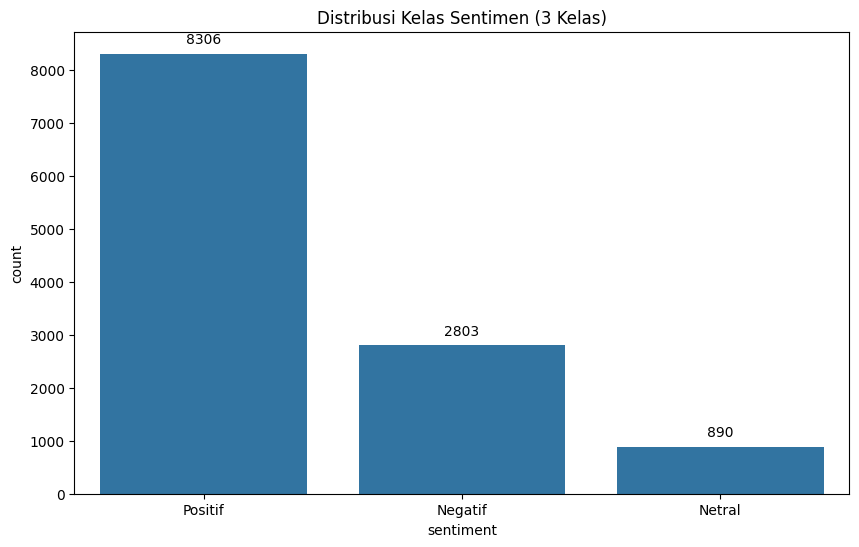

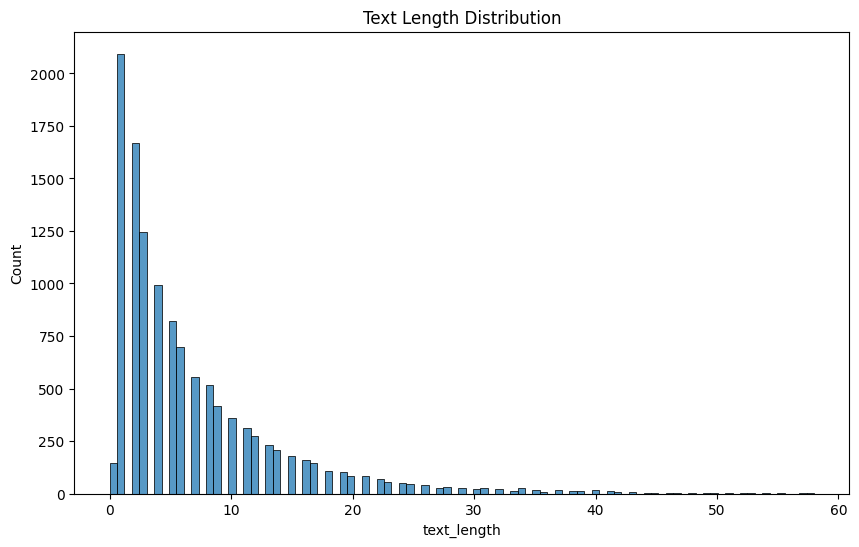

<Figure size 1200x600 with 0 Axes>

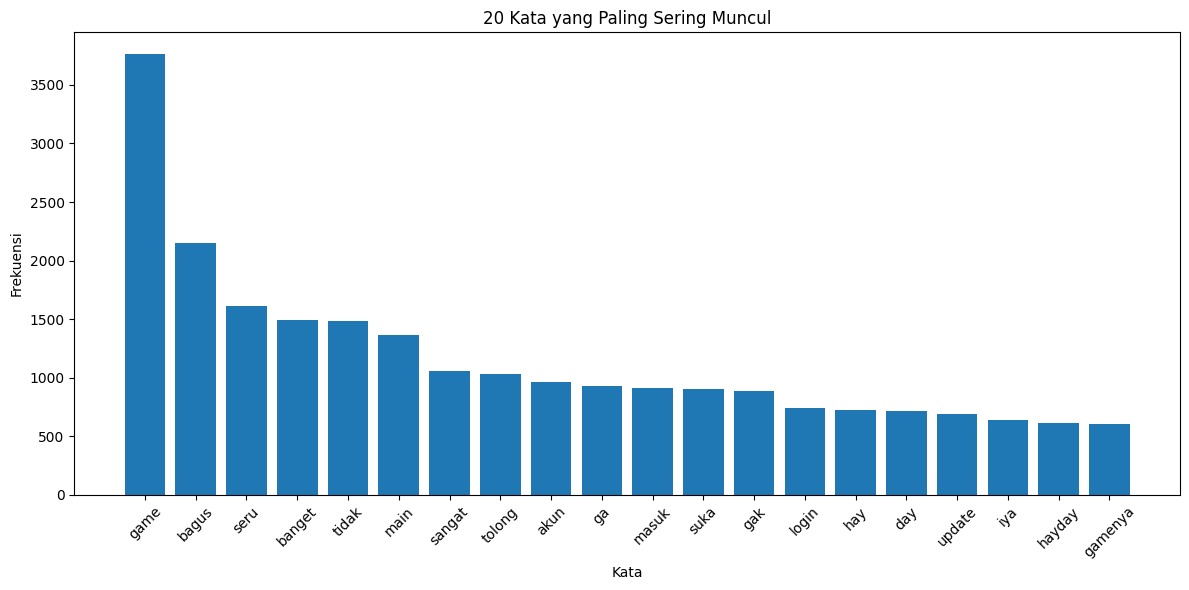

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter

# Set the figure size
plt.figure(figsize=(10, 6))

# Check class distribution using the correct 3-class 'sentiment' column
class_dist_plot = sns.countplot(x='sentiment', data=clean_df)
plt.title('Distribusi Kelas Sentimen (3 Kelas)')

# Add counts above the bars on the plot
for p in class_dist_plot.patches:
    class_dist_plot.annotate(format(p.get_height(), '.0f'),
                              (p.get_x() + p.get_width() / 2., p.get_height()),
                              ha='center', va='center',
                              xytext=(0, 10),
                              textcoords='offset points')

plt.show()

# Set the figure size
plt.figure(figsize=(10, 6))

# Visualize text length distribution
clean_df['text_length'] = clean_df['text_akhir'].apply(lambda x: len(str(x).split()))
sns.histplot(clean_df['text_length'])
plt.title('Text Length Distribution')
plt.show()

# Set the figure size
plt.figure(figsize=(12, 6))

# Visualize most frequent words
all_words = []
for text in clean_df['text_akhir']:
    all_words.extend(str(text).split())

word_freq = Counter(all_words)
most_common_words = word_freq.most_common(20)

words = [item[0] for item in most_common_words]
counts = [item[1] for item in most_common_words]

plt.figure(figsize=(12, 6))
plt.bar(words, counts)

plt.title('20 Kata yang Paling Sering Muncul')
plt.xlabel('Kata')
plt.ylabel('Frekuensi')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import accuracy_score, precision_score

# 🤖 Langkah 6: Pembagian Data & Pemodelan Eksperimen

Bagian ini dibagi secara sistematis menjadi beberapa sub-skema:
* **6.1**: Persiapan Data & Label Encoding
* **6.2**: Split Dataset Utama (80/20)
* **6.3**: Ekstraksi Fitur TF-IDF
* **6.4**: Skema 1 - Bidirectional LSTM (Deep Learning 80/20)
* **6.5**: Skema 2 - LinearSVC + TF-IDF (Classic ML 80/20)
* **6.6**: Skema 3 - LinearSVC + TF-IDF (Classic ML 70/30)
* **6.7**: Ringkasan Perbandingan Performa Skema

In [ ]:
# ======================================================================
# SUB-SECTION 5.1: PERSIAPAN DATA & LABEL ENCODING
# ======================================================================
from sklearn.preprocessing import LabelEncoder
import pandas as pd

# 1. Ambil salinan df mentah
clean_df = df.copy()

print("[INFO] Memproses ulang prapemrosesan teks terpadu...")
clean_df['text_clean'] = clean_df['content'].apply(cleaningText)
clean_df['text_casefoldingText'] = clean_df['text_clean'].apply(casefoldingText)
clean_df['text_slangwords'] = clean_df['text_casefoldingText'].apply(fix_slangwords)
clean_df['text_tokenizingText'] = clean_df['text_slangwords'].apply(tokenizingText)
clean_df['text_stopword'] = clean_df['text_tokenizingText'].apply(filteringText)
clean_df['text_akhir'] = clean_df['text_stopword'].apply(toSentence)

# 2. Filter data untuk klasifikasi biner (Positif & Negatif)
df_binary_main = clean_df[clean_df['sentiment'] != 'Netral'].copy()

# 3. Encode Label Target Biner
encoder_bin = LabelEncoder()
y_bin_main = encoder_bin.fit_transform(df_binary_main['sentiment'])
X_bin_main = df_binary_main['text_akhir']

print("\n[INFO] Label target biner berhasil dikonfigurasi:")
for idx, label in enumerate(encoder_bin.classes_):
    print(f"   * Label: {label:<10} -> Kode: {idx}")

[INFO] Memproses ulang prapemrosesan teks terpadu...

[INFO] Label target biner berhasil dikonfigurasi:
   * Label: Negatif    -> Kode: 0
   * Label: Positif    -> Kode: 1


In [ ]:
# ======================================================================
# SUB-SECTION 5.2: SPLIT DATASET UTAMA (80/20)
# ======================================================================
from sklearn.model_selection import train_test_split

# Membagi dataset menjadi training (80%) dan testing (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X_bin_main,
    y_bin_main,
    test_size=0.20,
    random_state=42,
    stratify=y_bin_main
)

print("==================================================")
print("===       DISTRIBUSI DATASET UTAMA (80/20)     ===")
print("==================================================")
print(f"Jumlah Data Training : {len(X_train)} sampel")
print(f"Jumlah Data Testing  : {len(X_test)} sampel")
print("==================================================")

===       DISTRIBUSI DATASET UTAMA (80/20)     ===
Jumlah Data Training : 8887 sampel
Jumlah Data Testing  : 2222 sampel


In [ ]:
# ======================================================================
# SUB-SECTION 5.3: EKSTRAKSI FITUR TF-IDF
# ======================================================================
from sklearn.feature_extraction.text import TfidfVectorizer

print("[INFO] Melakukan ekstraksi fitur teks menggunakan TF-IDF...")
tfidf_smote = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=5, sublinear_tf=True)
X_train_tfidf_sm = tfidf_smote.fit_transform(X_train)
X_test_tfidf_sm = tfidf_smote.transform(X_test)

print(f"Dimensi matriks fitur TF-IDF Train : {X_train_tfidf_sm.shape}")
print(f"Dimensi matriks fitur TF-IDF Test  : {X_test_tfidf_sm.shape}")

[INFO] Melakukan ekstraksi fitur teks menggunakan TF-IDF...
Dimensi matriks fitur TF-IDF Train : (8887, 2172)
Dimensi matriks fitur TF-IDF Test  : (2222, 2172)


In [ ]:
# ======================================================================
# SUB-SECTION 5.4: SKEMA PELATIHAN 1 (BI-LSTM DEEP LEARNING - 80/20)
# ======================================================================
print("===================================================================")
print("===     MEMULAI EVALUASI SKEMA 1: BIDIRECTIONAL LSTM (80/20)    ===")
print("===================================================================")

import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, accuracy_score
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SpatialDropout1D, LSTM, Dense, Bidirectional, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf

max_words = 5000
max_len = 80

# Tokenisasi Teks
tokenizer = Tokenizer(num_words=max_words, lower=True, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_s1 = pad_sequences(X_train_seq, maxlen=max_len)
X_test_s1 = pad_sequences(X_test_seq, maxlen=max_len)

# Penanganan Imbalanced Class via Weighting
class_weights_array = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights_dict = dict(enumerate(class_weights_array))

# Definisi Arsitektur Model
model_lstm = Sequential([
    Embedding(input_dim=max_words, output_dim=100, input_length=max_len),
    SpatialDropout1D(0.2),
    Bidirectional(LSTM(64, dropout=0.2, recurrent_dropout=0.2)),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model_lstm.compile(
    loss='binary_crossentropy',
    optimizer=tf.keras.optimizers.Adam(learning_rate=2e-3),
    metrics=['accuracy']
)

early_stop = EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True)

# Pelatihan Model
history = model_lstm.fit(
    X_train_s1, y_train,
    epochs=6,
    batch_size=128,
    validation_data=(X_test_s1, y_test),
    class_weight=class_weights_dict,
    callbacks=[early_stop],
    verbose=1
)

acc_train_s1 = model_lstm.evaluate(X_train_s1, y_train, verbose=0)[1]
acc_test_s1 = model_lstm.evaluate(X_test_s1, y_test, verbose=0)[1]

y_pred_s1_prob = model_lstm.predict(X_test_s1, verbose=0)
y_pred_s1 = (y_pred_s1_prob > 0.5).astype(int).flatten()

print("\n====================== HASIL EVALUASI SKEMA 1 ======================")
print(f"Akurasi Pelatihan (Train Accuracy) : {acc_train_s1 * 100:.2f}%")
print(f"Akurasi Pengujian (Test Accuracy)  : {acc_test_s1 * 100:.2f}%")
print("====================================================================\n")
print("Classification Report Skema 1:")
print(classification_report(y_test, y_pred_s1, target_names=encoder_bin.classes_))

===     MEMULAI EVALUASI SKEMA 1: BIDIRECTIONAL LSTM (80/20)    ===
Epoch 1/6
70/70 ━━━━━━━━━━━━━━━━━━━━ 53s 534ms/step - accuracy: 0.7648 - loss: 0.4860 - val_accuracy: 0.8389 - val_loss: 0.3692
Epoch 2/6
70/70 ━━━━━━━━━━━━━━━━━━━━ 38s 508ms/step - accuracy: 0.8695 - loss: 0.3186 - val_accuracy: 0.8420 - val_loss: 0.3759
Epoch 3/6
70/70 ━━━━━━━━━━━━━━━━━━━━ 42s 596ms/step - accuracy: 0.8999 - loss: 0.2582 - val_accuracy: 0.8263 - val_loss: 0.4115
Epoch 4/6
70/70 ━━━━━━━━━━━━━━━━━━━━ 34s 481ms/step - accuracy: 0.9143 - loss: 0.2269 - val_accuracy: 0.8501 - val_loss: 0.4293
Epoch 5/6
70/70 ━━━━━━━━━━━━━━━━━━━━ 34s 485ms/step - accuracy: 0.9249 - loss: 0.2012 - val_accuracy: 0.8555 - val_loss: 0.3873
Epoch 6/6
70/70 ━━━━━━━━━━━━━━━━━━━━ 33s 467ms/step - accuracy: 0.9327 - loss: 0.1773 - val_accuracy: 0.8492 - val_loss: 0.4579

====================== HASIL EVALUASI SKEMA 1 ======================
Akurasi Pelatihan (Train Accuracy) : 94.55%
Akurasi Pengujian (Test Accuracy)  : 85.55%

Class

In [ ]:
# ======================================================================
# SUB-SECTION 5.5: SKEMA PELATIHAN 2 (LINEARSVC + TF-IDF - 80/20)
# ======================================================================
print("===================================================================")
print("===     MEMULAI EVALUASI SKEMA 2: LINEARSVC + TF-IDF (80/20)    ===")
print("===================================================================")

from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

model_svc_smote = LinearSVC(C=0.5, class_weight='balanced', random_state=42)
model_svc_smote.fit(X_train_tfidf_sm, y_train)

acc_train_s2 = accuracy_score(y_train, model_svc_smote.predict(X_train_tfidf_sm))
acc_test_s2 = accuracy_score(y_test, model_svc_smote.predict(X_test_tfidf_sm))
y_pred_s2 = model_svc_smote.predict(X_test_tfidf_sm)

print("\n====================== HASIL EVALUASI SKEMA 2 ======================")
print(f"Akurasi Pelatihan (Train Accuracy) : {acc_train_s2 * 100:.2f}%")
print(f"Akurasi Pengujian (Test Accuracy)  : {acc_test_s2 * 100:.2f}%")
print("====================================================================\n")
print("Classification Report Skema 2:")
print(classification_report(y_test, y_pred_s2, target_names=encoder_bin.classes_))

===     MEMULAI EVALUASI SKEMA 2: LINEARSVC + TF-IDF (80/20)    ===

====================== HASIL EVALUASI SKEMA 2 ======================
Akurasi Pelatihan (Train Accuracy) : 90.93%
Akurasi Pengujian (Test Accuracy)  : 85.28%

Classification Report Skema 2:
              precision    recall  f1-score   support

     Negatif       0.66      0.85      0.74       561
     Positif       0.94      0.85      0.90      1661

    accuracy                           0.85      2222
   macro avg       0.80      0.85      0.82      2222
weighted avg       0.87      0.85      0.86      2222



In [ ]:
# ======================================================================
# SUB-SECTION 5.6: SKEMA PELATIHAN 3 (LINEARSVC + TF-IDF - 70/30)
# ======================================================================
print("===================================================================")
print("===     MEMULAI EVALUASI SKEMA 3: LINEARSVC + TF-IDF (70/30)    ===")
print("===================================================================")

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

X_s3 = df_binary_main['text_akhir']
y_s3 = y_bin_main

# Split 70/30 khusus untuk Skema 3
X_text_train_s3, X_text_test_s3, y_train_s3, y_test_s3 = train_test_split(
    X_s3,
    y_s3,
    test_size=0.30,
    random_state=42,
    stratify=y_s3
)

tfidf_s3 = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=5, sublinear_tf=True)
X_train_tfidf_s3 = tfidf_s3.fit_transform(X_text_train_s3)
X_test_tfidf_s3 = tfidf_s3.transform(X_text_test_s3)

model_svc = LinearSVC(C=0.5, class_weight='balanced', random_state=42)
model_svc.fit(X_train_tfidf_s3, y_train_s3)

acc_train_s3 = accuracy_score(y_train_s3, model_svc.predict(X_train_tfidf_s3))
acc_test_s3 = accuracy_score(y_test_s3, model_svc.predict(X_test_tfidf_s3))
y_pred_s3 = model_svc.predict(X_test_tfidf_s3)

print("\n====================== HASIL EVALUASI SKEMA 3 ======================")
print(f"Akurasi Pelatihan (Train Accuracy) : {acc_train_s3 * 100:.2f}%")
print(f"Akurasi Pengujian (Test Accuracy)  : {acc_test_s3 * 100:.2f}%")
print("====================================================================\n")
print("Classification Report Skema 3:")
print(classification_report(y_test_s3, y_pred_s3, target_names=encoder_bin.classes_))

===     MEMULAI EVALUASI SKEMA 3: LINEARSVC + TF-IDF (70/30)    ===

====================== HASIL EVALUASI SKEMA 3 ======================
Akurasi Pelatihan (Train Accuracy) : 90.88%
Akurasi Pengujian (Test Accuracy)  : 85.12%

Classification Report Skema 3:
              precision    recall  f1-score   support

     Negatif       0.66      0.84      0.74       841
     Positif       0.94      0.86      0.90      2492

    accuracy                           0.85      3333
   macro avg       0.80      0.85      0.82      3333
weighted avg       0.87      0.85      0.86      3333



In [62]:
# ======================================================================
# SUB-SECTION 5.7: RINGKASAN PERBANDINGAN KETIGA SKEMA PELATIHAN
# ======================================================================
print("==================================================")
print("=== RINGKASAN PERBANDINGAN KOMPARATIF MODEL ===")
print("==================================================")

hasil_model = pd.DataFrame({
    "Skema Pelatihan": [
        "Skema 1: Bidirectional LSTM (80/20)",
        "Skema 2: LinearSVC + TF-IDF (80/20)",
        "Skema 3: LinearSVC + TF-IDF (70/30)"
    ],
    "Train Accuracy (%)": [
        f"{acc_train_s1*100:.2f}%",
        f"{acc_train_s2*100:.2f}%",
        f"{acc_train_s3*100:.2f}%"
    ],
    "Test Accuracy (%)": [
        f"{acc_test_s1*100:.2f}%",
        f"{acc_test_s2*100:.2f}%",
        f"{acc_test_s3*100:.2f}%"
    ]
})

display(hasil_model)

=== RINGKASAN PERBANDINGAN KOMPARATIF MODEL ===


,Skema Pelatihan,Train Accuracy (%),Test Accuracy (%)
0,Skema 1: Bidirectional LSTM (80/20),94.55%,85.55%
1,Skema 2: LinearSVC + TF-IDF (80/20),90.93%,85.28%
2,Skema 3: LinearSVC + TF-IDF (70/30),90.88%,85.12%


# ⚖️ Langkah 7: Penanganan Class Imbalance (SMOTE) & Evaluasi Lengkap

[INFO] Menerapkan SMOTE pada training data untuk penyeimbangan kelas...
Sebelum SMOTE - Negatif: 2242, Positif: 6645
Setelah SMOTE - Negatif: 6645, Positif: 6645

====================== REPORT EVALUASI MODEL (SMOTE + LinearSVC) ======================
              precision    recall  f1-score   support

     Negatif       0.59      0.83      0.69       561
     Positif       0.93      0.81      0.86      1661

    accuracy                           0.81      2222
   macro avg       0.76      0.82      0.78      2222
weighted avg       0.85      0.81      0.82      2222



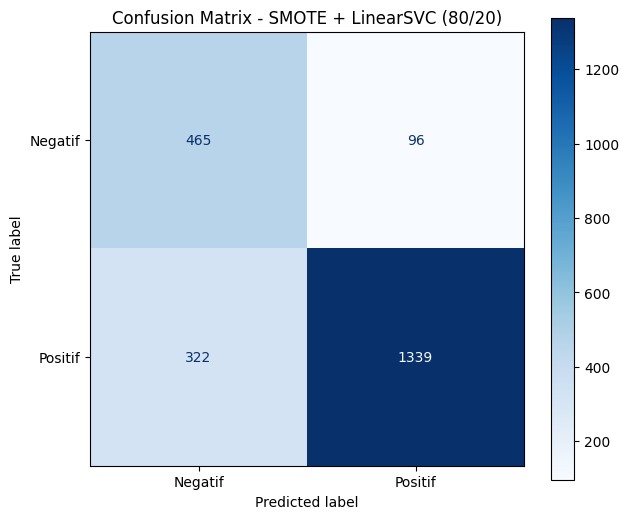

In [ ]:
# Pastikan pustaka imbalanced-learn terinstal
!pip install -q imbalanced-learn

from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Terapkan SMOTE hanya pada Data Latih
print("[INFO] Menerapkan SMOTE pada training data untuk penyeimbangan kelas...")
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_tfidf_sm, y_train)

# Menampilkan distribusi kelas sebelum dan setelah SMOTE
print(f"Sebelum SMOTE - Negatif: {sum(y_train == 0)}, Positif: {sum(y_train == 1)}")
print(f"Setelah SMOTE - Negatif: {sum(y_train_resampled == 0)}, Positif: {sum(y_train_resampled == 1)}")

# 2. Latih Model SVC Baru dengan Data yang telah Diresample
model_svc_balanced = LinearSVC(C=0.5, random_state=42)
model_svc_balanced.fit(X_train_resampled, y_train_resampled)

# 3. Prediksi Data Uji
y_pred_balanced = model_svc_balanced.predict(X_test_tfidf_sm)

# 4. Tampilkan Classification Report Lengkap
print("\n====================== REPORT EVALUASI MODEL (SMOTE + LinearSVC) ======================")
print(classification_report(y_test, y_pred_balanced, target_names=encoder_bin.classes_))

# 5. Visualisasikan Confusion Matrix
fig, ax = plt.subplots(figsize=(7, 6))
cm = confusion_matrix(y_test, y_pred_balanced)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=encoder_bin.classes_)
disp.plot(cmap='Blues', ax=ax)
plt.title('Confusion Matrix - SMOTE + LinearSVC (80/20)')
plt.grid(False)
plt.show()

# 🔍 Langkah 8: Analisis Kesalahan (Error Analysis) & Visualisasi Proyeksi t-SNE

In [ ]:
import pandas as pd
import numpy as np

# 1. Mengidentifikasi sampel data uji yang salah klasifikasi
df_test_analysis = pd.DataFrame({
    'Teks_Asli': clean_df.loc[X_test.index, 'content'],
    'Teks_Bersih': X_test,
    'Aktual': y_test,
    'Prediksi': y_pred_balanced
})

# Filter baris yang salah prediksi
errors = df_test_analysis[df_test_analysis['Aktual'] != df_test_analysis['Prediksi']]

# Dekode kembali label numerik ke teks asli ('Negatif' / 'Positif')
errors['Aktual_Label'] = encoder_bin.inverse_transform(errors['Aktual'])
errors['Prediksi_Label'] = encoder_bin.inverse_transform(errors['Prediksi'])

print(f"Total Kesalahan Prediksi pada Data Uji: {len(errors)} dari {len(y_test)} sampel")
print("\n--- 5 Contoh Kesalahan Klasifikasi Teratas ---")
display(errors[['Teks_Asli', 'Aktual_Label', 'Prediksi_Label']].head(10))

Total Kesalahan Prediksi pada Data Uji: 418 dari 2222 sampel

--- 5 Contoh Kesalahan Klasifikasi Teratas ---


,Teks_Asli,Aktual_Label,Prediksi_Label
2944,Hayday has become very quiet. Many of my frien...,Positif,Negatif
5251,"Kenapa jadi lemot,,, gak bisa dibuka weee😬😬😬. ...",Positif,Negatif
2760,"sistem masuk permainan tetap ribet atau susah,...",Negatif,Positif
4085,sebelum daftar di Supercell ada bonus iklan da...,Negatif,Positif
10943,gaa seruu,Negatif,Positif
3998,"WOIII AKUN AKU KELUAR SENDIRIII, MANA SEMUA PA...",Positif,Negatif
7322,Jadi ga bisa d pake maen hayday ya setelah di ...,Positif,Negatif
6691,"Awesome, really makes my day",Positif,Negatif
5695,eror terus kecewA,Positif,Negatif
7307,Jangan banyak update tolong,Negatif,Positif


In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# 2. Ambil sampel subset data untuk visualisasi t-SNE agar tidak terlalu lambat
print("[INFO] Menghitung proyeksi t-SNE untuk visualisasi fitur (ini mungkin memerlukan waktu beberapa saat)... ")

tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000)
X_tsne = tsne.fit_transform(X_test_tfidf_sm.toarray())

# Plot visualisasi 2D
plt.figure(figsize=(10, 8))
for label_idx, label_name in enumerate(encoder_bin.classes_):
    indices = np.where(y_test == label_idx)
    plt.scatter(X_tsne[indices, 0], X_tsne[indices, 1], label=label_name, alpha=0.6, edgecolors='none')

plt.title('Proyeksi Fitur TF-IDF Menggunakan t-SNE (Kumpulan Data Uji)')
plt.xlabel('Komponen t-SNE 1')
plt.ylabel('Komponen t-SNE 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

[INFO] Menghitung proyeksi t-SNE untuk visualisasi fitur (ini mungkin memerlukan waktu beberapa saat)... 


# ⚙️ Langkah 9: Optimasi Hyperparameter Menggunakan GridSearchCV

In [ ]:
from sklearn.model_selection import GridSearchCV

# Tentukan rentang parameter C yang akan diuji
param_grid = {'C': [0.01, 0.1, 0.5, 1.0, 10.0]}

print("[INFO] Memulai pencarian hyperparameter terbaik dengan GridSearchCV...")
grid_search = GridSearchCV(
    LinearSVC(class_weight='balanced', random_state=42),
    param_grid,
    cv=5,
    scoring='f1_macro',
    verbose=1
)

grid_search.fit(X_train_tfidf_sm, y_train)

print(f"\n[HASIL] Parameter Terbaik: {grid_search.best_params_}")
print(f"[HASIL] F1-Macro Terbaik   : {grid_search.best_score_:.4f}")

[INFO] Memulai pencarian hyperparameter terbaik dengan GridSearchCV...
Fitting 5 folds for each of 5 candidates, totalling 25 fits

[HASIL] Parameter Terbaik: {'C': 0.1}
[HASIL] F1-Macro Terbaik   : 0.8270


# ☁️ Langkah 10: Visualisasi Word Cloud Sentimen

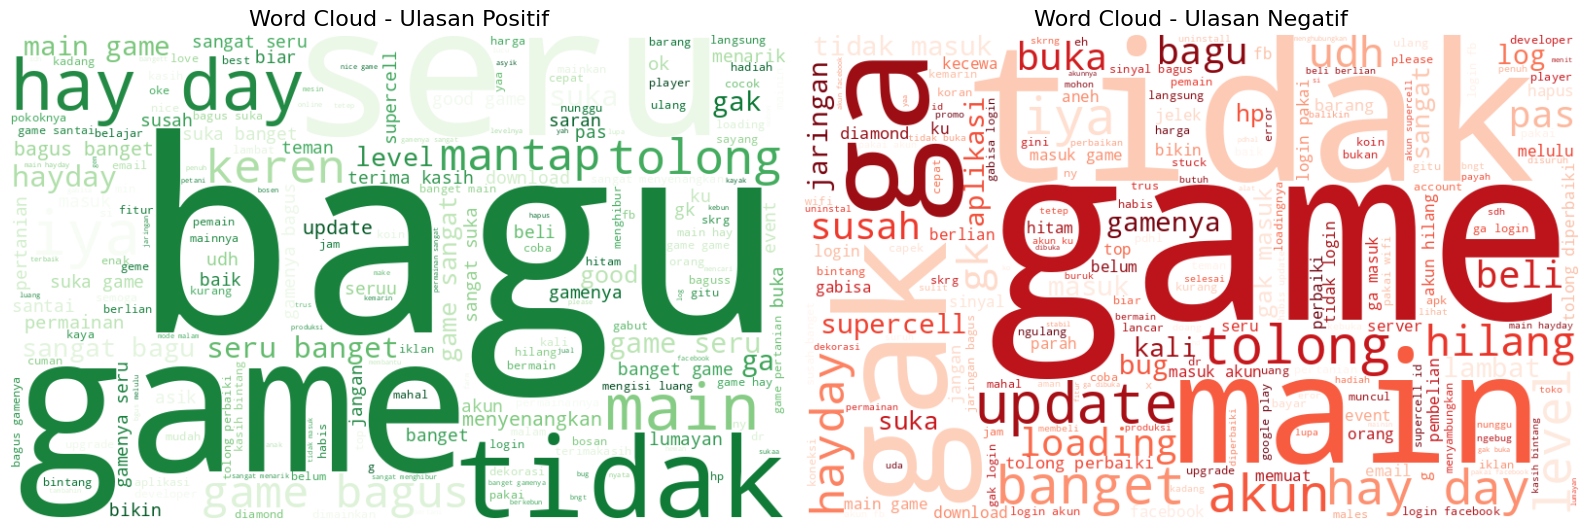

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Pisahkan teks berdasarkan sentimen asli
teks_positif = " ".join(clean_df[clean_df['sentiment'] == 'Positif']['text_akhir'])
teks_negatif = " ".join(clean_df[clean_df['sentiment'] == 'Negatif']['text_akhir'])

fig, axs = plt.subplots(1, 2, figsize=(16, 8))

# Word Cloud Positif
wordcloud_pos = WordCloud(width=800, height=500, background_color='white', colormap='Greens').generate(teks_positif)
axs[0].imshow(wordcloud_pos, interpolation='bilinear')
axs[0].set_title('Word Cloud - Ulasan Positif', fontsize=16)
axs[0].axis('off')

# Word Cloud Negatif
wordcloud_neg = WordCloud(width=800, height=500, background_color='white', colormap='Reds').generate(teks_negatif)
axs[1].imshow(wordcloud_neg, interpolation='bilinear')
axs[1].set_title('Word Cloud - Ulasan Negatif', fontsize=16)
axs[1].axis('off')

plt.tight_layout()
plt.show()

# 🚀 Langkah 11: Pengujian Prediksi (Inference Testing) dengan Teks Baru

In [ ]:
### 🛠️ Pengujian Inference ###

print("=== PENGUJIAN INFERENCE DENGAN MODEL TERBAIK (LSTM - BINER) ===\n")

def preprocess_text_inference(text):
    text = cleaningText(text)
    text = casefoldingText(text)
    text = fix_slangwords(text)
    text = tokenizingText(text)
    text = filteringText(text)
    text = toSentence(text)
    return text

# Kumpulan teks baru
teks_baru = [
    "Wah gila game ini seru banget bikin nagih, mantap Supercell!",
    "Sangat mengecewakan, akun saya tiba-tiba hilang padahal sudah level tinggi.",
    "Biasa aja sih gamenya, lumayan buat ngisi waktu luang kalau lagi bosen.",
    "Bikin emosi main game ini, koin lama banget ngumpulinya tapi harga barang mahal!"
]

# 1. Bersihkan teks
teks_bersih = [preprocess_text_inference(t) for t in teks_baru]

# 2. Konversi ke sekuens menggunakan tokenizer LSTM
seq_baru = tokenizer.texts_to_sequences(teks_bersih)
pad_baru = pad_sequences(seq_baru, maxlen=max_len)

# 3. Prediksi probabilitas menggunakan model LSTM Biner
prediksi_prob = model_lstm.predict(pad_baru)

# 4. Ambil kelas berdasarkan threshold 0.5
prediksi_kelas = (prediksi_prob > 0.5).astype(int).flatten()

# 5. Kembalikan kode angka menjadi teks label biner ('Negatif', 'Positif')
label_prediksi = encoder_bin.inverse_transform(prediksi_kelas)

# 6. Tampilkan hasil prediksi
for asli, bersih, pred in zip(teks_baru, teks_bersih, label_prediksi):
    print(f"Teks Asli   : {asli}")
    print(f"Teks Bersih : {bersih}")
    print(f"--> Sentimen: {pred}\n")

=== PENGUJIAN INFERENCE DENGAN MODEL TERBAIK (LSTM - BINER) ===

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
Teks Asli   : Wah gila game ini seru banget bikin nagih, mantap Supercell!
Teks Bersih : gila game seru banget bikin nagih mantap supercell
--> Sentimen: Positif

Teks Asli   : Sangat mengecewakan, akun saya tiba-tiba hilang padahal sudah level tinggi.
Teks Bersih : sangat mengecewakan akun tibatiba hilang level
--> Sentimen: Negatif

Teks Asli   : Biasa aja sih gamenya, lumayan buat ngisi waktu luang kalau lagi bosen.
Teks Bersih : gamenya lumayan mengisi luang bosen
--> Sentimen: Positif

Teks Asli   : Bikin emosi main game ini, koin lama banget ngumpulinya tapi harga barang mahal!
Teks Bersih : bikin emosi main game koin banget ngumpulinya harga barang mahal
--> Sentimen: Negatif



In [63]:
readme_content = """# 🌾 Proyek Analisis Sentimen Ulasan Hay Day

Proyek ini berfokus pada analisis sentimen ulasan pengguna game **Hay Day** di Google Play Store. Proyek ini mengimplementasikan pipeline pemrosesan teks bahasa Indonesia terstruktur dan membandingkan performa berbagai metode *Machine Learning* klasik serta *Deep Learning* (Bidirectional LSTM).

---

## 📊 Hasil Eksperimen & Performa Model

Berikut adalah perbandingan akurasi model dari 3 skema pelatihan utama yang dievaluasi:

| Skema Pelatihan | Train Accuracy | Test Accuracy |
| :--- | :---: | :---: |
| **Skema 1: Bidirectional LSTM (80/20)** | **94.55%** | **85.55%** |
| **Skema 2: LinearSVC + TF-IDF (80/20)** | 90.93% | 85.28% |
| **Skema 3: LinearSVC + TF-IDF (70/30)** | 90.88% | 85.12% |

### ⚖️ Penanganan Imbalance Class (SMOTE + LinearSVC 80/20)
Setelah menerapkan **SMOTE** untuk menyeimbangkan kelas minoritas (Negatif), model **LinearSVC** menghasilkan distribusi performa yang lebih seimbang antara presisi dan recall:
* **Akurasi Keseluruhan**: **81%**
* **F1-Score (Negatif)**: **0.69** (Recall naik drastis menjadi **83%**)
* **F1-Score (Positif)**: **0.86**

---

## 🛠️ Alur Pipeline Pra-Pemrosesan Teks
Setiap ulasan mentah melewati tahap pembersihan intensif sebelum masuk ke tahap pemodelan:
1. **Cleaning**: Menghapus mention (@), hashtag (#), RT, URL, angka, dan tanda baca.
2. **Case Folding**: Mengubah seluruh teks menjadi huruf kecil (*lowercase*).
3. **Slangwords Correction**: Memetakan kata-kata gaul/singkatan ke kata baku (contoh: *bgt* -> *banget*, *yg* -> *yang*).
4. **Tokenization**: Pemotongan kalimat menjadi token kata individual.
5. **Stopwords Filtering**: Mengeliminasi kata-kata tidak bermakna dengan tetap mempertahankan kata kunci sentimen (seperti *tidak, kurang, bagus, jelek*).
6. **Stemming (Opsional)**: Reduksi kata ke bentuk dasar menggunakan pustaka `Sastrawi`.

---

## 📂 Struktur Proyek
```directory
├── ulasan_hayday_mentah.csv  # Dataset ulasan mentah (~12.000 baris)
├── README.md                 # Dokumentasi Proyek
└── Proyek_Analisis_Sentimen.ipynb # Notebook Utama Alur Eksperimen
```

---

## 🚀 Panduan Instalasi & Penggunaan

### 1. Prasyarat Sistem
Pastikan Anda telah menginstal pustaka yang diperlukan:
```bash
pip install google-play-scraper Sastrawi pandas numpy matplotlib seaborn scikit-learn tensorflow imbalanced-learn wordcloud nltk
```

### 2. Cara Menjalankan Pipeline & Inference
Untuk melakukan pengujian prediksi dengan teks baru secara mandiri menggunakan model LSTM yang telah dilatih:

```python
# Contoh melakukan inference prediksi
texts = ["Gamenya seru banget, grafiknya juga luar biasa!", "Sering crash setelah update baru, kecewa."]
cleaned_texts = [preprocess_text_inference(t) for t in texts]
sequences = tokenizer.texts_to_sequences(cleaned_texts)
padded = pad_sequences(sequences, maxlen=80)

predictions = (model_lstm.predict(padded) > 0.5).astype(int)
```
"""

with open('README.md', 'w', encoding='utf-8') as f:
    f.write(readme_content)

print("[INFO] File README.md berhasil dibuat di workspace!")


[INFO] File README.md berhasil dibuat di workspace!
